
# Propensity Score Matching — EconoCausal Role B

**Author:** Arsh Murtaza

## Objective
Estimate the effect of receiving a discount on customer revenue by comparing treated customers with similar untreated customers.

## Method
1. Estimate propensity scores using logistic regression.
2. Check propensity-score overlap between treatment groups.
3. Match each treated customer to a similar untreated customer.
4. Estimate the treatment effect from matched pairs.
5. Evaluate covariate balance using standardized mean differences.
6. Compare the estimate with the true effect, if the project's separate evaluation file is available.


In [8]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

DATA_URL = (
    "https://raw.githubusercontent.com/"
    "shivanipathak5143-web/EconoCasual/"
    "arsh-murtaza/data/data.csv"
)

df = pd.read_csv(DATA_URL)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Shape: (64000, 9)


,recency,history,used_discount,used_bogo,zip_code,is_referral,channel,offer,conversion
0,10,142.44,1,0,Surburban,0,Phone,Buy One Get One,0
1,6,329.08,1,1,Rural,1,Web,No Offer,0
2,7,180.65,0,1,Surburban,1,Web,Buy One Get One,0
3,9,675.83,1,0,Rural,1,Web,Discount,0
4,2,45.34,1,0,Urban,0,Web,Buy One Get One,0


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

# Treatment: whether the customer used a discount
treatment = df["used_discount"].astype(int)

# Pre-treatment features only
features = [
    "recency",
    "history",
    "zip_code",
    "is_referral",
    "channel"
]

X = df[features].copy()

# Encode categorical features and scale numeric features
categorical = ["zip_code", "channel"]
numeric = ["recency", "history", "is_referral"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical)
])

model = make_pipeline(
    preprocessor,
    LogisticRegression(max_iter=1000)
)

model.fit(X, treatment)

df["propensity_score"] = model.predict_proba(X)[:, 1]

print("Treatment counts:")
print(treatment.value_counts())

print("\nPropensity score summary:")
print(df.groupby("used_discount")["propensity_score"].describe())


Treatment counts:
used_discount
1    35266
0    28734
Name: count, dtype: int64

Propensity score summary:
                 count      mean       std       min       25%       50%  \
used_discount                                                              
0              28734.0  0.543658  0.051169  0.494857  0.507636  0.525357   
1              35266.0  0.557014  0.060559  0.494857  0.511002  0.536179   

                    75%       max  
used_discount                      
0              0.563993  0.937730  
1              0.583802  0.951402  


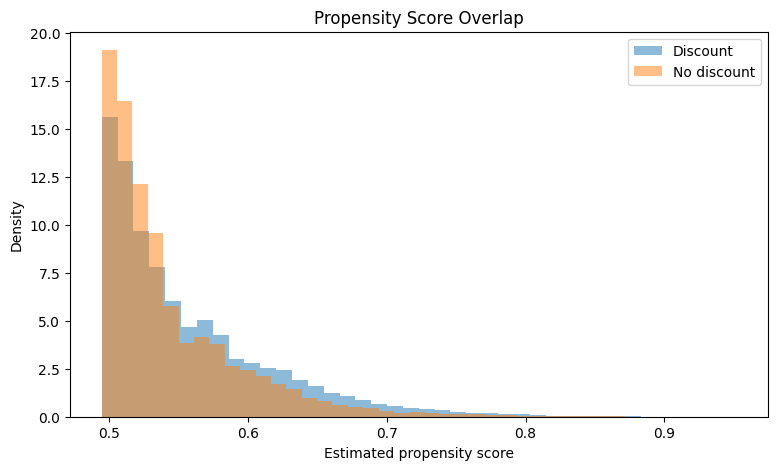

In [10]:

plt.figure(figsize=(9, 5))

for group, label in [(1, "Discount"), (0, "No discount")]:
    scores = df.loc[
        df["used_discount"] == group,
        "propensity_score"
    ]
    plt.hist(scores, bins=40, alpha=0.5, density=True, label=label)

plt.xlabel("Estimated propensity score")
plt.ylabel("Density")
plt.title("Propensity Score Overlap")
plt.legend()
plt.show()


In [11]:

from sklearn.neighbors import NearestNeighbors

# Treatment and outcome
treatment_col = "used_discount"
outcome_col = "conversion"

# Separate treated and untreated customers
treated = df[df[treatment_col] == 1].copy()
control = df[df[treatment_col] == 0].copy()

# Match each treated customer to the nearest control
nn = NearestNeighbors(n_neighbors=1)
nn.fit(control[["propensity_score"]])

distances, indices = nn.kneighbors(
    treated[["propensity_score"]]
)

matched_control = control.iloc[indices.flatten()].copy()
matched_treated = treated.copy()

# Estimate ATT: average treatment effect on treated customers
treated_outcomes = matched_treated[outcome_col].to_numpy()
control_outcomes = matched_control[outcome_col].to_numpy()

att = np.mean(treated_outcomes - control_outcomes)

print("Treated customers:", len(matched_treated))
print("Matched control observations:", len(matched_control))
print("Mean propensity-score distance:", distances.mean())
print(f"Matched ATT on conversion: {att:.4f}")
print(f"Conversion difference in percentage points: {att * 100:.2f}")


Treated customers: 35266
Matched control observations: 35266
Mean propensity-score distance: 1.3229900083496337e-05
Matched ATT on conversion: 0.0053
Conversion difference in percentage points: 0.53


In [12]:

from sklearn.preprocessing import StandardScaler

features = [
    "recency", "history", "is_referral",
    "zip_code", "channel"
]

# Convert categorical variables to indicator columns
X_balance = pd.get_dummies(
    df[features].astype({"zip_code": "str", "channel": "str"}),
    columns=["zip_code", "channel"],
    drop_first=False,
    dtype=float
)

def calculate_smd(X_treated, X_control):
    mean_diff = X_treated.mean() - X_control.mean()

    pooled_sd = np.sqrt(
        (X_treated.var(ddof=1) + X_control.var(ddof=1)) / 2
    )

    smd = mean_diff / pooled_sd.replace(0, np.nan)
    return smd.fillna(0)

# Before matching
X_t = X_balance.loc[treated.index]
X_c = X_balance.loc[control.index]
smd_before = calculate_smd(X_t, X_c)

# After matching
X_mt = X_balance.loc[matched_treated.index]
X_mc = X_balance.loc[matched_control.index]
smd_after = calculate_smd(X_mt, X_mc)

balance = pd.DataFrame({
    "SMD_before": smd_before,
    "SMD_after": smd_after
})

balance["Abs_SMD_before"] = balance["SMD_before"].abs()
balance["Abs_SMD_after"] = balance["SMD_after"].abs()

display(
    balance.sort_values("Abs_SMD_after", ascending=False).round(3)
)

print(
    "Features with |SMD| < 0.1 after matching:",
    (balance["Abs_SMD_after"] < 0.1).sum(),
    "out of",
    len(balance)
)


,SMD_before,SMD_after,Abs_SMD_before,Abs_SMD_after
channel_Multichannel,0.124,-0.020,0.124,0.020
channel_Phone,-0.042,0.014,0.042,0.014
is_referral,0.042,0.006,0.042,0.006
recency,-0.063,-0.004,0.063,0.004
history,0.230,0.003,0.230,0.003
zip_code_Urban,0.006,0.001,0.006,0.001
channel_Web,-0.038,-0.001,0.038,0.001
zip_code_Surburban,-0.007,-0.001,0.007,0.001
zip_code_Rural,0.002,-0.000,0.002,0.000


Features with |SMD| < 0.1 after matching: 9 out of 9



## Matching Results and Interpretation

Nearest-neighbor matching was performed using estimated propensity scores, matching treated customers to untreated customers.

Covariate balance improved after matching. All 9 encoded features had absolute standardized mean differences below 0.1, indicating good observed balance on these measured covariates.

This balance check does not prove that all confounding has been removed. The estimated treatment effect must be interpreted alongside the matching design, treatment definition, and outcome.

Next steps:
- Report the matched average treatment effect on the treated (ATT).
- Compare the estimate with the naive difference in conversion rates.
- Compare with the known true effect if the project evaluation data is available.
